In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [2]:

data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

df.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:

df.shape


(569, 31)

In [4]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [5]:

df['target'].value_counts()


target
1    357
0    212
Name: count, dtype: int64

In [6]:

X = df.drop('target', axis=1)
y = df['target']


In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [8]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [9]:

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)


LogisticRegression(max_iter=1000)

In [10]:

y_pred = model.predict(X_test)

print("Predicted Values:", y_pred[:10])
print("Actual Values:", y_test.values[:10])


Predicted Values: [0 1 0 1 0 1 1 0 0 0]
Actual Values: [0 1 0 1 0 1 1 0 0 0]


In [11]:

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")


Accuracy: 0.9824561403508771
Accuracy Percentage: 98.24561403508771 %


In [12]:

cm = confusion_matrix(y_test, y_pred)

print(cm)


[[41  1]
 [ 1 71]]


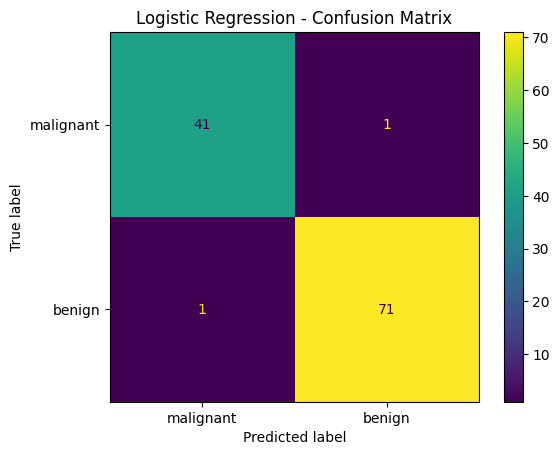

In [13]:

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()


In [14]:

print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))


              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



C:\Users\HP\AppData\Roaming\Python\Python39\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


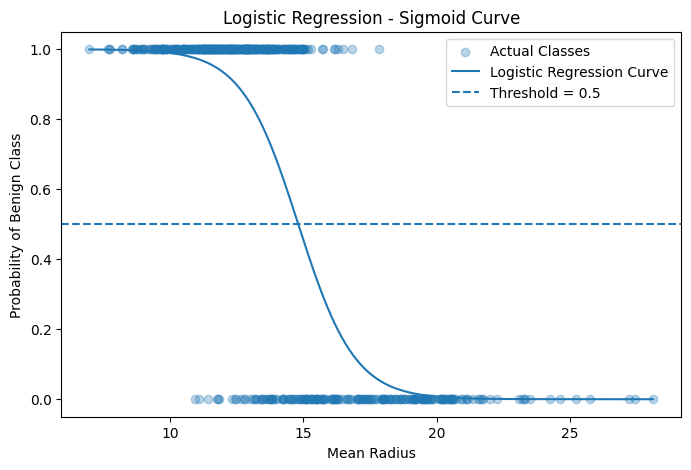

In [15]:

from sklearn.pipeline import make_pipeline

# Use one feature for visualization
X_single = df[['mean radius']]
y_single = df['target']

# Train a separate single-feature model
log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

log_model.fit(X_single, y_single)

# Generate values for the curve
x_range = np.linspace(
    X_single['mean radius'].min(),
    X_single['mean radius'].max(),
    300
).reshape(-1, 1)

# Probability of class 1 (benign)
y_prob = log_model.predict_proba(x_range)[:, 1]

# Draw graph
plt.figure(figsize=(8, 5))

plt.scatter(
    X_single['mean radius'],
    y_single,
    alpha=0.3,
    label="Actual Classes"
)

plt.plot(
    x_range,
    y_prob,
    label="Logistic Regression Curve"
)

plt.axhline(y=0.5, linestyle='--', label="Threshold = 0.5")

plt.xlabel("Mean Radius")
plt.ylabel("Probability of Benign Class")
plt.title("Logistic Regression - Sigmoid Curve")
plt.legend()
plt.show()
